# 07 · The shortlist: from an account name to 10 candidate groups

**The question this step answers:** for one company account, which 10 of the 190 standard groups are most likely the right one? Every mapping method later picks from these same 10 (or says "none"), so this shortlist is the ceiling of the whole system.

**Where it sits in the pipeline:** the first step of the mapper. Its input is an account name from notebooks 03–05; its output, 10 candidates with a score each, goes to every mapping method. Notebook 08 compares the models that can do this step; this notebook shows how it works with the chosen one, **bge-m3**.

**The code:** `src/d1/mapper/embed.py` (text → vectors) and `src/d1/mapper/retrieve.py` (`Retriever.top_k(names, k)`).

*Running this notebook loads bge-m3 (2.2 GB, downloaded once into `~/.cache/huggingface/`).*

*Re-run on 2026-11-06 after the account names were cleaned of company, bank and brand names (notebook 04, section 3b).*

In [1]:
import json
from collections import Counter
from random import Random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from d1.config import REPO_ROOT, load_config
from d1.datagen.standard_chart import load_standard_chart
from d1.evaluation.plotting import (
    BLUE_RAMP, COLORS, INK, INK_2, LANGUAGE_COLORS, MUTED, SINGLE, SOURCE_COLORS, SURFACE, apply_style, pct, short,
)

config = load_config()
chart = load_standard_chart(config.data.chart_path, expected=config.data.expected_groups)
by_code = {a.code: a for a in chart}
apply_style()
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.max_rows", 60)

import time
from d1.mapper.embed import SentenceTransformerEmbedder
from d1.mapper.retrieve import Retriever, standard_text
from d1.datagen.schema import read_jsonl

import contextlib, io, warnings
warnings.filterwarnings("ignore")

K = config.models.mapping.candidates_k
embedder = SentenceTransformerEmbedder(config.models.embedding_model)
with contextlib.redirect_stderr(io.StringIO()):  # hide the model's loading messages
    embedder.encode(["warm-up"], "query")
retriever = Retriever(embedder, chart, cache_dir=REPO_ROOT / ".cache" / "embeddings")
dev = read_jsonl(config.data.generated_dir / "dev.jsonl")
print(f"model: {embedder.model_id}; standard-group vectors: {retriever.standard_embeddings.shape} (groups x numbers)")

model: BAAI/bge-m3; standard-group vectors: (190, 1024) (groups x numbers)


## 1. The account we follow

An LLM-written dev account of a construction company, with its right answer:

In [2]:
account = next(r for r in dev if r.name == "En-cours chantier Uccle - Av. Brugmann")
display(pd.Series({"name": account.name, "language": account.language, "source": account.source,
                   "right group": f"{account.target_code} {by_code[account.target_code].name_en}"}, name=account.account_id).to_frame())

,dev-c041-009
name,En-cours chantier Uccle - Av. Brugmann
language,mixed
source,llm
right group,320 Work in Progress - Acquisition Value


## 2. Step 1: every standard group becomes one text, then one vector

Each group is described by its three names and its parent (notebook 01 explains why the parent is there):

In [3]:
target = by_code[account.target_code]
print(standard_text(target))

Work in Progress - Acquisition Value | Goederen in bewerking - Aanschaffingswaarde | En-cours de fabrication - Valeur d'acquisition (Work in Progress)


The model turns that text into a vector: a list of 1,024 numbers that captures what it *means*. It is scaled to length 1, so comparing two vectors is a single dot product. The first 8 of the 1,024 numbers for group 320:

In [4]:
row = retriever.codes.index(target.code)
v = retriever.standard_embeddings[row]
print(np.round(v[:8], 4), "...")
print(f"{len(v)} numbers, length {np.linalg.norm(v):.4f}")

[ 0.0035  0.0445 -0.0346  0.0518 -0.0231  0.0308 -0.0262  0.0547] ...
1024 numbers, length 1.0000


This happens once for all 190 groups. The result is saved in `.cache/embeddings/`, so the next run reads it from disk instead of computing it again.

## 3. Step 2: the account name becomes a vector too, and is compared with all 190

The account name is embedded the same way. Then one multiplication gives its **cosine similarity** with every group: 1 means the same direction (the same meaning), 0 means unrelated. All 190 scores for our account, highest first:

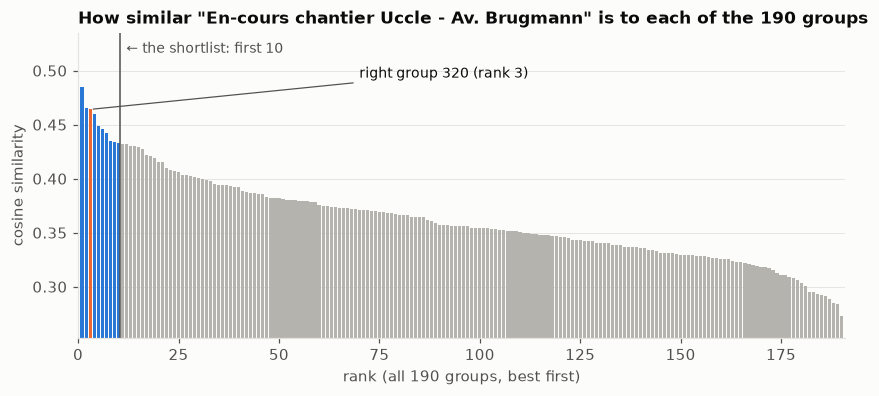

In [5]:
q = embedder.encode([account.name], "query")[0]
scores = retriever.standard_embeddings @ q
order = np.argsort(-scores, kind="stable")
ranked = pd.DataFrame({"code": [retriever.codes[i] for i in order], "score": scores[order]})
ranked["rank"] = np.arange(1, len(ranked) + 1)
right_rank = int(ranked.loc[ranked["code"] == account.target_code, "rank"].iloc[0])

fig, ax = plt.subplots(figsize=(9, 3.6))
colors = [COLORS[config.models.embedding_model] if c == account.target_code else (SINGLE if r <= K else MUTED) for c, r in zip(ranked["code"], ranked["rank"])]
ax.bar(ranked["rank"], ranked["score"], color=colors, width=0.8)
ax.axvline(K + 0.5, color=INK_2, linewidth=1)
low = ranked["score"].min()
ax.text(K + 2, ranked["score"].max() + 0.035, f"← the shortlist: first {K}", va="center", fontsize=9, color=INK_2)
ax.annotate(f"right group {account.target_code} (rank {right_rank})", (right_rank, ranked["score"].iloc[right_rank - 1]),
            xytext=(70, ranked["score"].max() + 0.012), textcoords="data", fontsize=9, color=INK, va="center",
            arrowprops={"arrowstyle": "-", "color": INK_2, "linewidth": 0.8})
ax.set_xlim(0, len(ranked) + 1)
ax.set_ylim(ranked["score"].min() - 0.02, ranked["score"].max() + 0.05)
ax.set_xlabel("rank (all 190 groups, best first)")
ax.set_ylabel("cosine similarity")
ax.grid(axis="x", visible=False)
ax.set_title(f'How similar "{account.name}" is to each of the 190 groups')
plt.show()

How to read it: every bar is one group. The blue bars are the 10 that make the shortlist, the orange bar is the right group, the grey ones are cut. Two things show:
- **The right group made the shortlist**, at rank 3. Any method can now pick it.
- **The scores are close together.** Even the worst groups aren't near 0, so a raw cosine score can't be read as a confidence. Calibration (notebook 09) turns it into one.

## 4. Step 3: keep the 10 best, and that's the shortlist

`top_k` does steps 2 and 3 in one call, for any number of accounts:

In [6]:
(shortlist,) = retriever.top_k([account.name], K)
display(pd.DataFrame([{"rank": i + 1, "group": c.code, "name": by_code[c.code].name_en, "score": round(c.score, 4),
                       "right?": "✔" if c.code == account.target_code else ""} for i, c in enumerate(shortlist)]).set_index("rank"))

,group,name,score,right?
rank,,,,
1,221,Buildings,0.4851,
2,370,Contracts in Progress - Acquisition Value,0.4652,
3,320,Work in Progress - Acquisition Value,0.4641,✔
4,491,Accrued Income,0.4595,
5,371,Contracts in Progress - Profit Recognized,0.4483,
6,717,Increase (Decrease) in Contracts in Progress,0.4459,
7,493,Deferred Income,0.4420,
8,499,Suspense Accounts,0.4349,
9,444,Invoices to Be Received,0.4343,


The first two candidates make sense for a reader too: *Buildings* (221) and *Contracts in Progress* (370) are both about construction. It takes the word "en-cours" (work in progress) to pick 320. That's exactly the choice the mapping methods will make.

## 5. When the shortlist misses

The same steps for "Gross wages shop staff", whose right group is 620 *Remuneration and Direct Social Benefits*:

In [7]:
miss = next(r for r in dev if r.name == "Gross wages shop staff")
(full,) = retriever.top_k([miss.name], len(chart))
rank = next(i for i, c in enumerate(full, start=1) if c.code == miss.target_code)
display(pd.DataFrame([{"rank": i + 1, "group": c.code, "name": by_code[c.code].name_en, "score": round(c.score, 4)} for i, c in enumerate(full[:5])]).set_index("rank"))
print(f"right group {miss.target_code} is at rank {rank} of {len(chart)}: not on the shortlist, so no method can pick it")

,group,name,score
rank,,,
1,623,Other Personnel Costs,0.4374
2,602,"Purchases of Services, Works and Studies",0.4315
3,713,Increase (Decrease) in Stocks of Finished Goods,0.4241
4,603,Subcontracting,0.4239
5,754,Exchange Differences,0.4207


right group 620 is at rank 47 of 190: not on the shortlist, so no method can pick it


The model links "wages" with *Other Personnel Costs* (623), *Purchases of Services* (602) and *Subcontracting* (603), all costs of work done for the company, but not with "remuneration" in group 620's official name. Notebook 08 counts how often this happens: 12.5% of dev accounts with bge-m3.

## 6. The whole dev pile at once

The same call for all 3,500 dev accounts. Repeated names are embedded once, and the 190 group vectors come from the cache:

In [8]:
start = time.perf_counter()
shortlists = retriever.top_k([r.name for r in dev], K)
seconds = time.perf_counter() - start
on_list = np.mean([r.target_code in [c.code for c in s] for r, s in zip(dev, shortlists)])
print(f"{len(dev)} accounts in {seconds:.1f} s ({len({r.name for r in dev})} distinct names); right group on the shortlist: {on_list:.1%}")

3500 accounts in 8.9 s (2965 distinct names); right group on the shortlist: 87.5%


## 7. What is *not* happening

- **Nothing is trained.** bge-m3 is used exactly as downloaded. Only the comparison of vectors happens here.
- **No choice is made yet.** The shortlist is 10 candidates in score order. Picking one, or saying "none", is the job of the mapping methods, and deciding whether to trust that pick is the job of calibration (notebook 09).
- **No vector database.** 190 targets are tiny: one matrix multiplication scores thousands of names in a fraction of a second.